In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl

In [39]:
df = pd.read_excel('Dataset.xlsx')
display(df.info())
display(df.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          19 non-null     int64  
 1   Name          19 non-null     str    
 2   Platform      19 non-null     str    
 3   Year          19 non-null     int64  
 4   Genre         19 non-null     str    
 5   Publisher     19 non-null     str    
 6   NA_Sales      16 non-null     float64
 7   EU_Sales      17 non-null     float64
 8   JP_Sales      18 non-null     float64
 9   Other_Sales   17 non-null     float64
 10  Global_Sales  17 non-null     float64
dtypes: float64(5), int64(2), str(4)
memory usage: 1.8 KB


None

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,NaN,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,NaN,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,NaN,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,NaN,31.37
5,6,Tetris,GB,1989,Puzzle,Nintendo,23.20,2.26,4.22,0.58,NaN
6,7,New Super Mario Bros.,DS,2006,Platform,Nintendo,11.38,9.23,6.50,2.90,30.01
7,8,Wii Play,Wii,2006,Misc,Nintendo,NaN,9.20,2.93,2.85,29.02
8,9,New Super Mario Bros. Wii,Wii,2009,Platform,Nintendo,14.59,7.06,4.70,2.26,28.62
9,10,Duck Hunt,NES,1984,Shooter,Nintendo,26.93,0.63,0.28,0.47,28.31


In [40]:
# handling rows with missing data
display(df.isna().sum())
print(f"Percentage of missing values:\n {(df.isna().sum().sum()) / df.shape[0] * 100:.2f}%")

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        3
EU_Sales        2
JP_Sales        1
Other_Sales     2
Global_Sales    2
dtype: int64

Percentage of missing values:
 52.63%


The percentage of missing values is roughly more than half of the dataset which is quite huge, thus making it not a good choice to delete. Therefore, imputation is the next alternative. Given that the all the fields are the sales fields (numerical), imputing with the mean (provided there are no outliers to skew the results) or the median would be the appropriate choice.

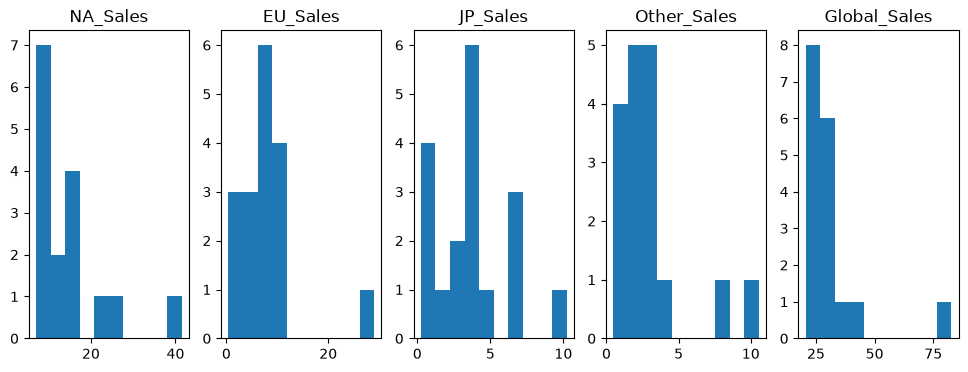

In [65]:
plt.figure(figsize=(12,4))

plt.subplot(1,5,1)
plt.hist(df["NA_Sales"])
plt.title("NA_Sales")

plt.subplot(1,5,2)
plt.hist(df["EU_Sales"])
plt.title("EU_Sales")

plt.subplot(1,5,3)
plt.hist(df["JP_Sales"])
plt.title("JP_Sales")

plt.subplot(1,5,4)
plt.hist(df["Other_Sales"])
plt.title("Other_Sales")

plt.subplot(1,5,5)
plt.hist(df["Global_Sales"])
plt.title("Global_Sales")

plt.show()

Before proceeding to check for outliers, the visualization above show that the data is not normally distributed, thus, I will use the 1.5IQR method for outlier detection.

In [67]:
def get_outliers(series: pd.Series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = series[(series < lower_bound) | (series > upper_bound)]
    return outliers

for variable in ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]:
    print(get_outliers(df[variable]))
    print()

0    41.49
9    26.93
Name: NA_Sales, dtype: float64

0    29.02
Name: EU_Sales, dtype: float64

4    10.22
Name: JP_Sales, dtype: float64

0      8.46
17    10.57
Name: Other_Sales, dtype: float64

0    82.74
Name: Global_Sales, dtype: float64



This is an extremely small dataset with outliers. Therefore, they will be left as they are. However, given that outliers are present, imputation will be done using the median.